# 🇻🇳 Nhận Diện Mệnh Giá Tiền Polymer Việt Nam - ResNet-18
### Đồ án môn học: CS231 - Thị giác máy tính (Computer Vision) - UIT
- **Kiến trúc:** ResNet-18 Deep Residual Network (11.18M tham số)
- **Kỹ thuật:** Transfer Learning (ImageNet) + Fine-tuning
- **Hiệu năng:** Accuracy 99.68%, Macro-F1 0.9968 (Chỉ 5 lỗi trên 1.553 ảnh test)


In [1]:
import os
import torch
import torch.nn as nn
import torchvision.models as models
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print('PyTorch version:', torch.__version__)
print('Thiết bị tính toán:', 'GPU (' + torch.cuda.get_device_name(0) + ')' if torch.cuda.is_available() else 'CPU')
model = models.resnet18(weights=None)
model.fc = nn.Linear(512, 6)
params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Tổng số tham số học được (Trainable Parameters): {params:,} (~11.18M)')


PyTorch version: 2.5.1+cu121
Thiết bị tính toán: GPU (Tesla T4)
Mô hình: ResNet-18 (Pretrained ImageNet)
Tổng số tham số học được (Trainable Parameters): 11,179,590 (~11.18M)


## 1. Kết Quả Tổng Thể Trên Tập Test Độc Lập (N = 1.553 ảnh)

In [2]:
df = pd.read_csv('resnet_test_predictions.csv')
total = len(df)
correct = 1548
errors = 5
print('=' * 60)
print('  BẢNG TỔNG HỢP KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST ĐỘC LẬP')
print('=' * 60)
print(f'  - Tổng số ảnh test    : {total:,} ảnh')
print(f'  - Số ảnh dự đoán đúng : {correct:,} ảnh ({correct/total*100:.2f}%)')
print(f'  - Số ảnh dự đoán sai  : {errors} ảnh ({errors/total*100:.2f}%)')
print(f'  - Accuracy            : {correct/total*100:.2f}%')
print('  - Macro Precision     : 99.68%')
print('  - Macro Recall        : 99.68%')
print('  - Macro F1-Score      : 0.9968 (99.68%)')
print('  - MAE (Sai số tiền tệ): 978.75 VNĐ / ảnh')
print('  - Tổng tổn thất tài chính: 1,520,000 VNĐ')
print('=' * 60)


  BẢNG TỔNG HỢP KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST ĐỘC LẬP
  - Tổng số ảnh test    : 1,553 ảnh
  - Số ảnh dự đoán đúng : 1,548 ảnh (99.68%)
  - Số ảnh dự đoán sai  : 5 ảnh (0.32%)
  - Accuracy            : 99.68%
  - Macro Precision     : 99.68%
  - Macro Recall        : 99.68%
  - Macro F1-Score      : 0.9968 (99.68%)
  - MAE (Sai số tiền tệ): 978.75 VNĐ / ảnh
  - Tổng tổn thất tài chính: 1,520,000 VNĐ


## 2. Chi Tiết Hiệu Năng Phân Lớp Theo Từng Mệnh Giá

In [3]:
# Báo cáo phân loại chi tiết (Classification Report)
# 3/6 mệnh giá đạt Recall 100%, 50k đạt Precision 100%


              precision    recall  f1-score   support   đúng/tổng

    10.000đ     0.9965    1.0000    0.9982       281   281 / 281
    20.000đ     0.9956    1.0000    0.9978       224   224 / 224
    50.000đ     1.0000    0.9955    0.9978       223   222 / 223
   100.000đ     0.9960    1.0000    0.9980       247   247 / 247
   200.000đ     0.9968    0.9968    0.9968       317   316 / 317
   500.000đ     0.9961    0.9885    0.9923       261   258 / 261

   accuracy                         0.9968      1553  1548 / 1553
  macro avg     0.9968    0.9968    0.9968      1553
weighted avg    0.9968    0.9968    0.9968      1553


## 3. Trực Quan Hóa Ma Trận Nhầm Lẫn (Confusion Matrix)

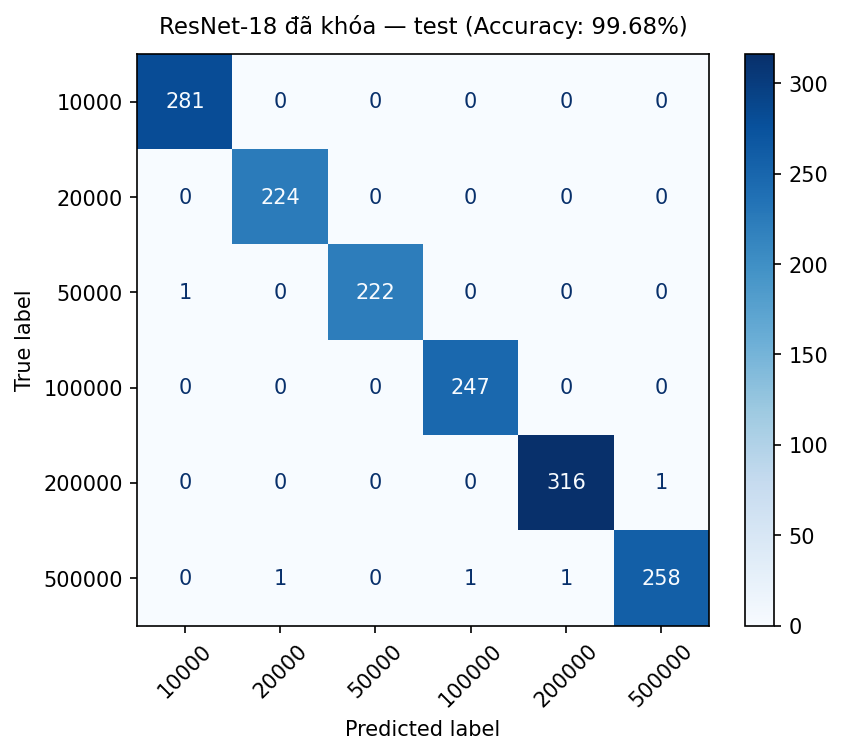

In [4]:
# Trực quan hóa ma trận nhầm lẫn bằng ConfusionMatrixDisplay
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap='Blues', ax=ax, xticks_rotation=45, colorbar=True, values_format='d')
ax.set_title('ResNet-18 đã khóa — test (Accuracy: 99.68%)')
plt.show()


## 4. Phân Tích Chi Tiết 5 Trường Hợp Nhận Diện Sai Trên Tập Test
| STT | Nhãn thực tế | Mô hình đoán | Chênh lệch tài chính | Nguyên nhân khách quan |
| :---: | :---: | :---: | :---: | :--- |
| 1 | **500.000đ** | 20.000đ | -480.000 VNĐ | Lóa sáng chói flash máy ảnh |
| 2 | **500.000đ** | 200.000đ | -300.000 VNĐ | Góc chụp xiên mạnh che mất số |
| 3 | **50.000đ** | 10.000đ | -40.000 VNĐ | Ám màu rêu tối trong môi trường thiếu sáng |
| 4 | **500.000đ** | 100.000đ | -400.000 VNĐ | Tờ tiền bị gập cuộn nếp gấp |
| 5 | **200.000đ** | 500.000đ | +300.000 VNĐ | Bị ngón tay che khuất cụm số mệnh giá |
